# Do the neurons that carry a fine-tune have an old job that names the task? (E101, 67M)

## The answer

No, not on this model. We wrote a one-line job from the Pile for each neuron that carries a fine-tune's gain, and asked
a judge whether that job relates to the task. Almost none did, for tasks built to reuse and tasks built to be new
alike. The method's own positive control failed too: neurons chosen from the original model because they fire hardest on
each task's answers were never judged related. So this reading cannot tell reuse from new on the 67M.

*Provisional: fast lane, no independent check. Full record: `reports/analyses/2026-11-05_analysis_e101-carrying-jobs.md`.*


## What we were trying to test

`GOALS.md` asks whether post-training reuses what a model already does or adds something new. The previous experiment,
E98, found for each of 43 saved fine-tunes of the 67M which MLP neurons of the original model carry the gain when they
fire differently with their weights unchanged. Call those neurons the fine-tune's **carrying set**. This experiment asks
what job those neurons had before training. If a fine-tune built to reuse an ability is carried by neurons whose old job
already relates to the task, and one built to be new is not, then a neuron's job reads reuse without any decomposition.
The labels "built to reuse" and "built to be new" describe how each task was made; they are assumptions, except copy
against lookup, which a check on the original model's copying head labelled.

We read each neuron the way the "already clean" essay reads neurons, in four steps, each by a separate agent that sees
only what the step needs:

1. **Pile windows.** Each neuron's 20 strongest windows from 2,000 Pile rows, with the peak token marked.
2. **Writer.** From those windows alone, a one-line job.
3. **Maximiser.** From the job alone, five texts that should fire the neuron and five near misses that should not. The
   model scores each text. A text fires **strongly** at 30% of the neuron's strongest Pile window or more, the essay's
   bar. The job **wins** when more examples than near misses fire strongly.
4. **Judge.** From the jobs and six one-line task descriptions, which tasks each job would plausibly help.

The **related share** of a set of neurons is the share whose job wins and is tied to the set's own task: 0 means no
neuron's job names the task, 1 means every one does.

Three kinds of neuron were mixed in the same batches. The **carrying** neurons come from eight groups of fine-tunes,
16 to 24 each. Each group has a **random partner** of the same size, matched by layer, which gives the floor: how often
an unrelated job is tied to a task. The **W₀ picks** are the positive control: on three tasks, the ten neurons outside
every carrying set that fire hardest at the answer position in the original model. If the method can tie anything to a
task, it should tie these.


## What we expected, and why

- **The judge would tie lowercase's carrying neurons to lowercase text.** Lowercase is the easiest case: ordinary
  English, which a model trained on web text has neurons for. We filed that its related share would beat the random
  floor by at least 0.2. If this failed, the method had no power, and the comparisons below would be reported but not
  read.
- **Built-to-reuse fine-tunes would read more related than built-to-be-new ones** on at least two of three pairs:
  lowercase against ciphers, same-word maps against random-word maps, copy against lookup.
- **The rank-1 maps' carrying neurons might be one coherent job.** Their update has rank one, so their carrying neurons
  could share a job, or be an artefact of the rank. No lean.
- **Before any agent ran,** lowercase's carrying neurons would already fire more at the answer position than the
  ciphers'. That measure is a quantile of each neuron's own Pile firing: 0.5 is a typical position, 1 its strongest.


In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

from commute.jobs import load_experiment

PLOT = load_experiment("carrying_jobs", "plot")
PLOT.main()  # redraws the three figures from the agent outputs and the key
FIG = Path("../experiments/carrying_jobs/figures")
score = json.loads(Path("../experiments/carrying_jobs/results/score.json").read_text())
print(f"neurons with every output: {score['complete']} of {score['n_neurons']}")


figures in experiments/carrying_jobs/figures
neurons with every output: 351 of 352


## What we observed

### Does the judge tie a carrying neuron's job to its task more than a random neuron's?


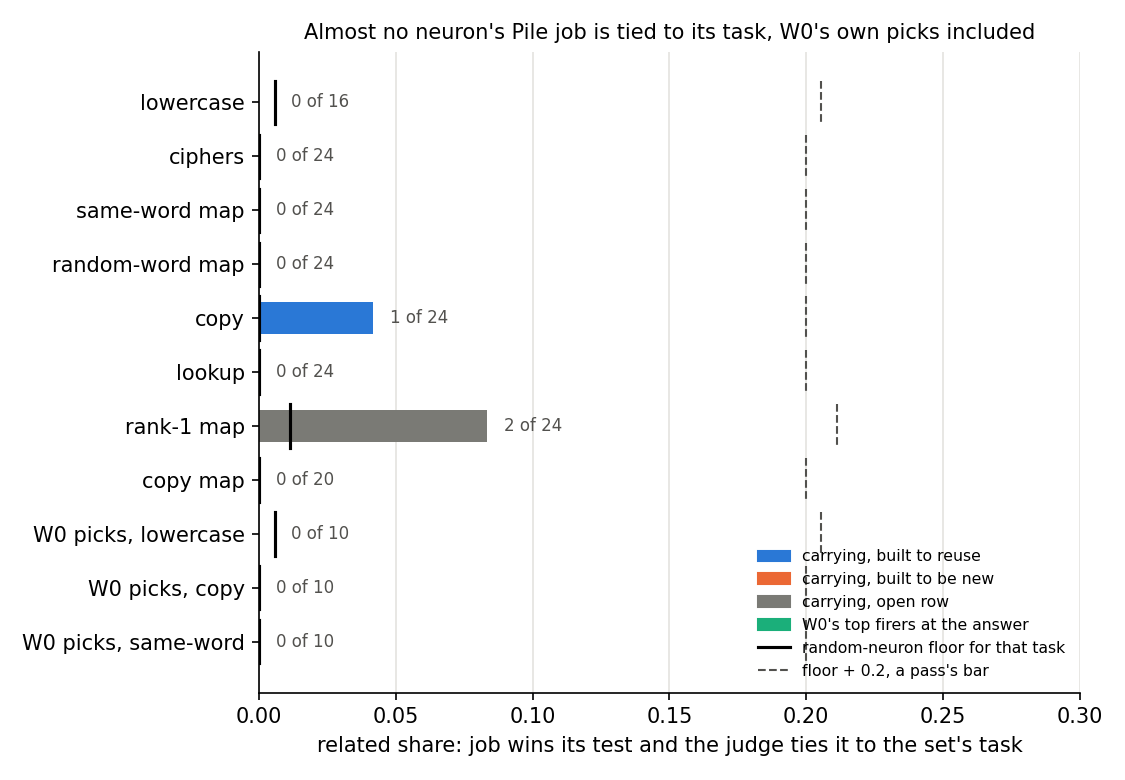

In [2]:
display(Image(FIG / "related_share.png", width=800))


**Reading it.** No, and the control says the method could not have. Lowercase's 16 carrying neurons were tied to
lowercase text zero times; the random floor was one in 179. The W₀ picks, chosen for firing on the task, were tied to
their task zero times on all three tasks. A pass needed the dashed line, the floor plus 0.2, and no bar reaches half of
it. Three of 150 carrying neurons were tied to their own task, all sensibly: one fires on a digit inside an identifier
that repeats earlier, tied to copying, and two fire on words like " type" before "of", tied to the rank-1 maps' next-word
task.

**Why the W₀ picks fail.** The neurons that fire hardest at the answer position are largely the same on every task, so
the thirty picks are only 22 distinct neurons. Their Pile jobs are about where a text starts, not what it says:

| neuron | picked on | its job, as written |
|---|---|---|
| 5100 | all three tasks | unclear: fires on the first token of a document or snippet (no preceding context) |
| 5424 | all three tasks | Fires on the <\|endoftext\|> token that ends one document and starts the next |
| 726 | copy | The sub-token "all" (or "back", "an") inside a longer word or identifier, e.g. "re\|all\|ocation" |

**Why lowercase's carrying neurons fail.** Most of their jobs are about where a sentence or heading ends:

| neuron | its job, as written |
|---|---|
| 7756 | A sentence-ending period (or ").") right after a citation, page number, or closing factual clause … just before the next sentence begins |
| 10742 | Words inside a title in capitalised title-case (song, album, speech names) |

Those are the positions where lowercase text differs from ordinary text, since the next word is the one whose case the
fine-tune changes. On our own reading after the fact, these neurons serve the task. The judge's brief ruled them out:
"a job that fires … on punctuation … helps none". It asked whether a job names the task, and a neuron one token before
the change does not name it.


### Are the 67M's neurons as clean as the essay's?


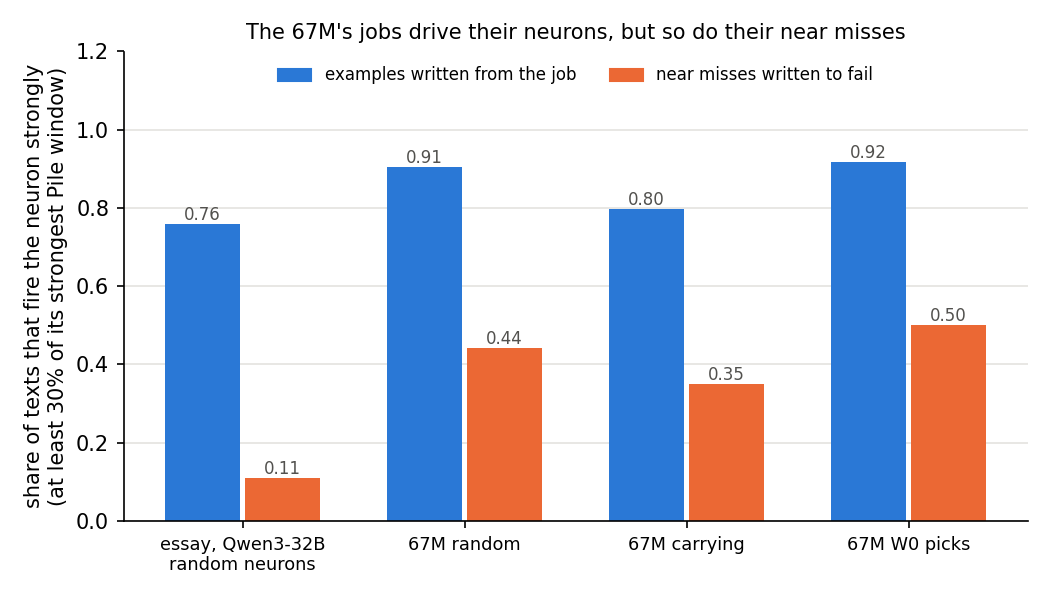

In [3]:
display(Image(FIG / "strong_rates.png", width=750))


**Reading it.** Partly. The jobs drive their neurons: 91% of the examples written for random neurons fired strongly,
against the essay's 76% on Qwen3-32B. But 44% of the near misses fired strongly too, four times the essay's 11%. A
random job still wins its test 82% of the time, against the essay's 90%, because winning only needs more strong
examples than strong near misses. So the 67M's neurons read cleanly as kinds of token, such as identifiers, digits,
sentence ends and word fragments, but a one-line job draws a loose boundary around what fires them.


### Are the rank-1 maps' carrying neurons more coherent than random ones?


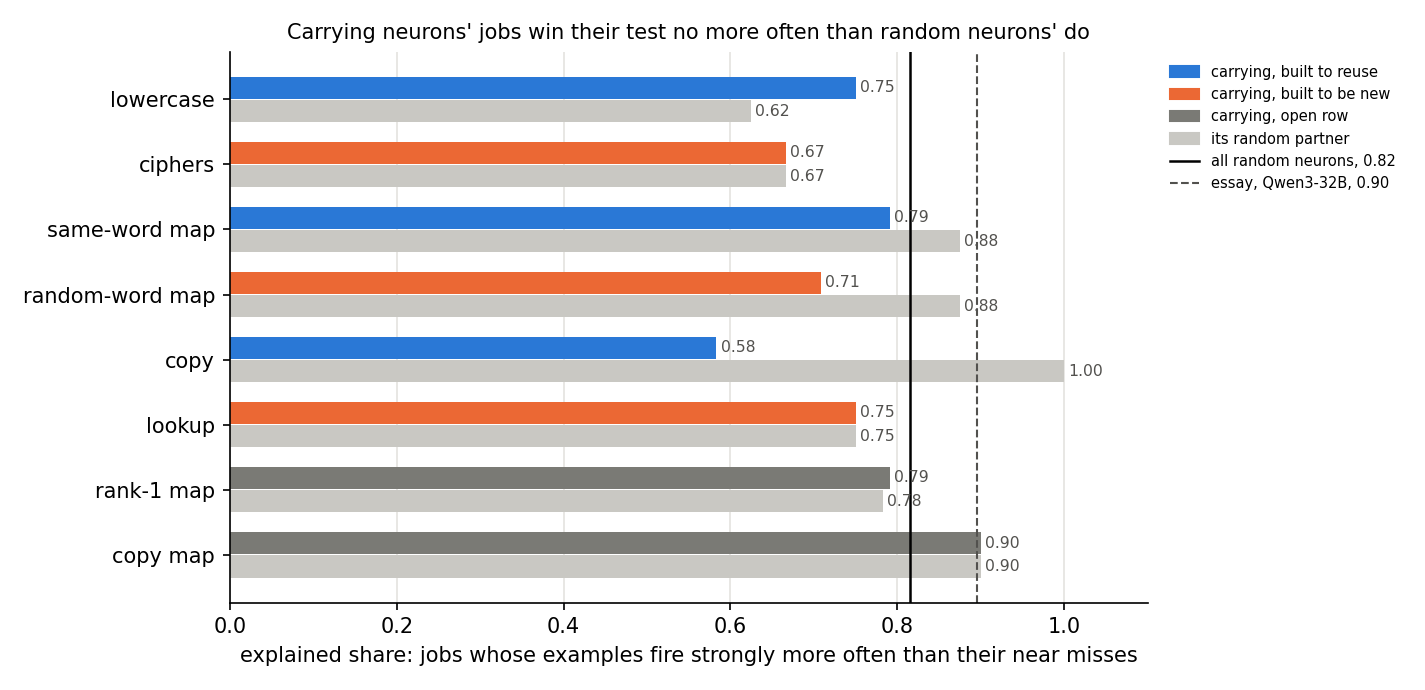

In [4]:
display(Image(FIG / "explained_share.png", width=900))


**Reading it.** No. The rank-1 maps' carrying neurons won their test 79% of the time, against 82% for all random
neurons and 78% for their own random partner. No carrying group beats its partner by much, and the copy group trails
its partner by 0.42. Since the power check failed first, this is reported, not read.

### Before the agents: were lowercase's carrying neurons already firing at the answer?

Barely. Lowercase's carrying set sat about 0.1 above its random sets in the engaged quantile, the ciphers' about 0.04.
The gap of 0.065 is larger than the seeds' spread but under the filed minimum of 0.2, so it reads no separation. Every
apparatus check held: held-out Pile read 0.50, and the neurons picked for firing on each task read 0.98 or more against
random sets near 0.5. The full table is in the report.


## What we learned

The essay's reading works on the 67M as a description: one-line jobs drive their neurons, and most name a kind of
token. It does not work as a reuse reader at this grain. The tasks are synthetic lookups and copies on marker and key
tokens, and a neuron can serve such a task without its Pile job naming it. For `GOALS.md`, a neuron being clean does not
by itself give a reuse-versus-new label, so the decomposition's reading gets no rival from this test on the 67M. Whether
the carrying neurons are reuse or new is left open: the test cannot see it either way.

## How compelling is the evidence

- **The null belongs to the method.** The W₀ picks read zero on all three tasks, so a zero on the carrying sets says
  nothing about reuse.
- **The control was weaker than planned.** The W₀ picks fire hard at the answer on every task, mostly as position
  neurons. Picks that fire on one task more than the others were not tried.
- **The judge is strict by brief.** It tied three of 179 random neurons to any task, and its brief excludes punctuation
  jobs, where lowercase's carrying neurons sit.
- **One agent of each kind per neuron,** groups of 16 to 24. Tasks covered: lowercase, two ciphers, same-word and
  random-word maps, copy and lookup, the rank-1 and copy maps.

## Surprises

- The planned positive control read zero. The neurons that fire hardest at the answer are one shared set across tasks.
- Lowercase's carrying neurons have coherent jobs at sentence and heading ends, where the task acts, and the judge's
  brief excluded them. Our reading after the fact, not a scored one.
- Near misses fire the 67M's neurons strongly four times as often as in the essay.

## What next

Whether any version of this reading has power on the 67M is the next experiment's question, not this one's.

- **Judge from the task's own windows.** Show the judge each task's windows with the answer marked, drop the
  punctuation exclusion, and pick controls that fire on one task more than the others. No GPU; the saved firing and the
  jobs suffice. If the new controls rise above the floor, rerun the carrying comparison.
- **If they do not,** move to Qwen3-1.7B with natural-language tasks, where jobs and task descriptions share words.


## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| C0 | the firing apparatus works | Pile 0.45-0.55; picks beat random by 0.2; null separates nothing | 0.50; 0.98 vs 0.5; none | pass |
| P0 | lowercase's set more engaged than ciphers' | gap ≥ 0.2 and > spread | 0.065 | fail |
| C1 | judge rarely ties random jobs | share ≤ 0.5 | 3/179 | pass |
| C2 | the win test works on Pile windows | win ≥ 0.8 | 0.92 | pass |
| P1 | lowercase carrying tied to lowercase | floor + 0.2, 2 se | 0/16 vs 1/179 | fail |
| P2 | reuse rows more related | 2 of 3 rows | 0 of 3 | fail, not read |
| P3 | rank-1 set coherent | base + 0.2, 2 se | 0.79 vs 0.82 | not coherent, not read |
| R | W₀ picks above floor | lean above | 0/10 on each task | below or level |

## Departures from the literature

From the essay's "Explanations That Could Lose" protocol, https://already-clean.goodfire.com/essay.md:

- The 67M and 2,000 Pile rows instead of Qwen3-32B and its corpus.
- A writer that sees 20 windows, with no tools, instead of an investigating agent.
- A stated win rule, more strong examples than strong near misses; the essay reports wins without stating its rule.
- Carrying and W₀-picked neurons beside random ones; the essay reads random neurons only.
- The judge and the engaged quantile are ours, not the essay's.
- The essay's distant-concept control was not run.

## Not run

- The essay's distant-concept control; controls picked for one task over the others; a judge shown the task's windows.
- A second agent of any kind per neuron; elicit and the rank-1 maps' cipher in the agent stage.
- Steering or ablating the carrying neurons; Qwen3-1.7B.
- One random neuron of 352 is unscored: its maximiser wrote all ten texts as examples and no near misses.

## Provenance

Stage 0: `experiments/carrying_jobs/results/stage0.json`, MATS `debug` job 52876, L40, about a minute, $0. An earlier
job, 52866, died on a missing results link. Agents: 36 Sonnet calls, `results/stage1/`. Maximiser scoring: job 52885,
`results/stage1/max_scores.json`. Score: `score.py score` → `results/score.json`. Figures: `plot.py`.
